# Nullspace cascade of the scattering bound

Bound on the scattered power $\tfrac12 I^H R_0 I$ of a structure carved out of the copper 2:1 plate (`*_patch21ka1.txt`, $ka = 1$ at 2.45 GHz,
plane wave $E_0 = 1$ kV/m), in the RWG basis with the non-diagonal material operator $Z_\mathrm{mat} = Z_s L$ and the scattered voltage
$x = V_\mathrm{sca} = -Z_0 I$ as the variable, as in `maxScatFixQ.ipynb` (without the $Q_W$ constraint).

At copper the optimal Lagrangian $L^\star = \operatorname{Sym} A(\lambda^\star)$ of the GCD dual has a near-kernel, so the dual current
$x^\star = A(\lambda^\star)^{-1} S(\lambda^\star)$ is not unique: the Lagrangian is (nearly) constant along the kernel, and any kernel component is
equally optimal for the dual. `maxScatFixQ.ipynb` fixes the kernel component by a least-squares completion of the constraint residuals. Here the
kernel component is instead fixed by a cascade of reduced QCQPs:

1. global bound and GCD bound,
2. split $x^\star$ into the range part $x_r = (1 - N N^H) x^\star$ (fixed) and the near-kernel $N$ of $L^\star$ (eigenvalues below $\epsilon$ times the
   largest),
3. restrict the QCQP to $x = x_r + N y$, with the same constraint set (the merged GCD constraints), and solve its dual in $y$,
4. repeat 2–3 on the reduced QCQP until its Lagrangian has no near-kernel,
   optionally refining each reduced level by GCD inside the kernel (`cascade(..., kerGCD=n)`, section Kernel GCD),
5. infer a structure from the resulting current by the pointwise fits.

**Reduction.** Every term of the QCQP has the form $f(x) = -x^H A x + 2\operatorname{Re}(x^H s) + c$ (objective: $A_0, s_0, c_0$; constraints:
$A_k = \operatorname{Sym}(A_1 P_k A_2)$ or $\operatorname{Sym}(A_2^H B_j A_2)$, $s_k = F_k$, $c_k$). At $x = x_0 + N y$,
$$f = -y^H (N^H A N) y + 2\operatorname{Re}\big(y^H N^H (s - A x_0)\big) + \big(-x_0^H A x_0 + 2\operatorname{Re}(x_0^H s) + c\big),$$
so the reduced QCQP has only general constraints ($B_j = N^H A_k N$, $s_{2j} = N^H(F_k - A_k x_0)$, $c_{2j}$) and is solved by
`DenseSharedProjQCQP` with an empty projector list. Its Lagrangian is $N^H A(\lambda) N$.

**Starting point.** At the parent multipliers, $N^H A(\lambda^\star) N$ holds the (small, positive) near-kernel eigenvalues, so $\lambda^\star$ is dual
feasible, and since the Lagrangian is constant on the kernel the reduced dual equals the parent dual there. Scaling the multipliers by
$1 + t$ gives $A = (1 + t) A(\lambda^\star) - t A_0$ with $-A_0 = \tfrac12 W^H R_0 W \succeq 0$, which moves the start off the PSD boundary.
The reduced dual is a minimum over a larger multiplier set (only $N^H A N \succeq 0$ is required), so it is at most the parent dual.

In [1]:
import contextlib
import copy
import io
import time

import matplotlib.pyplot as plt
import numpy as np
import scipy.io as sio
import scipy.linalg as la
import scipy.sparse as sp
from matplotlib.collections import LineCollection, PolyCollection
from matplotlib.colors import LogNorm
from scipy.optimize import least_squares

from dolphindes.cvxopt import DenseSharedProjQCQP, OptimizationHyperparameters
from dolphindes.cvxopt.gcd import GCDHyperparameters

In [2]:
matrixSet = "patch21ka1" # copper 2:1 plate, ka = 1; omW and the mesh exist for this set only (exportOmWpatch21ka1.m)

# Physical constants
epsilon_0 = 8.854e-12 # F/m
mu_0 = 4e-7 * np.pi # H/m
c = 1/np.sqrt(epsilon_0 * mu_0) # speed of light in vacuum
eta_0 = np.sqrt(mu_0/epsilon_0) # free-space impedance

E0 = 1e3 # plane wave amplitude in V/m

frequency = 2.45e9 # frequency in Hz
omega = 2 * np.pi * frequency # angular frequency

copper_conductivity = 5.96e7 # S/m
delta = np.sqrt(2 / (omega * mu_0 * copper_conductivity)) # skin depth in m
Zs = (1 + 1j) / (copper_conductivity * delta) # surface impedance
print(f"Surface impedance: {Zs} Ω")

Surface impedance: (0.012739130327240646+0.012739130327240646j) Ω


In [3]:
def Msym(M):
    return(0.5*(M.conj().T + M))

# Load matrices from text files (original RWG basis, no Cholesky transformation)
Lmat = np.loadtxt(f"Lmat_{matrixSet}.txt", delimiter=',') # lossy matrix
R0 = Msym(np.loadtxt(f"R0_{matrixSet}.txt", delimiter=',')) # radiated power matrix
X0 = Msym(np.loadtxt(f"X0_{matrixSet}.txt", delimiter=',')) # reactive power matrix
Vinc = E0*np.loadtxt(f"V_{matrixSet}.txt", delimiter=',').astype(complex) # voltage excitation vector

Ndes = Lmat.shape[0] # number of design variables
print(f"Matrix set: {matrixSet}, number of design variables: {Ndes}")

Zmat = Zs * Lmat # material impedance matrix (non-diagonal)
Z0 = R0 + 1j*X0 # free-space impedance matrix
Ztot = Z0 + Zmat # total impedance matrix
Ldiag = np.diag(Lmat).copy() # diagonal of the lossy matrix

def evalObj(Ivec):
    # scattered (radiated) power
    return(0.5*np.real(Ivec.conj() @ R0 @ Ivec))

# full plate performance
Ifull = np.linalg.solve(Ztot, Vinc)
Pfull = evalObj(Ifull)
print(f"Objective for full plate: {Pfull:.6e} W")

# reference: lossless resonant electric dipole, sigma_sca = 3 lambda^2 / (2 pi)
Pdip = 3*(c/frequency)**2/(2*np.pi) * E0**2/(2*eta_0)
print(f"resonant dipole scattered power: {Pdip:.4f} W")

Matrix set: patch21ka1, number of design variables: 233
Objective for full plate: 4.114174e-02 W
resonant dipole scattered power: 9.4884 W


104 nodes, 168 triangles, plate 35.05 x 17.00 mm, Lmat_nn = 0.481 l_n^2 (equilateral RWG): max rel. error 2.6e-14


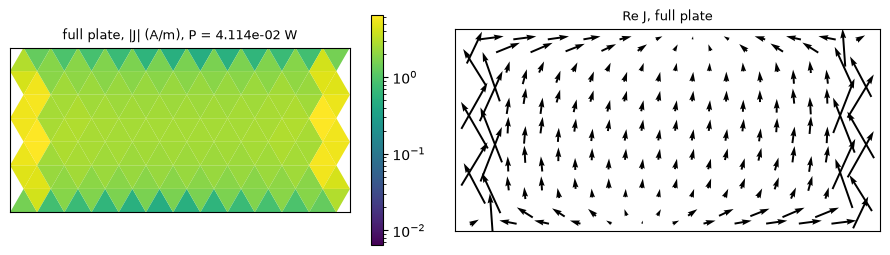

In [4]:
# mesh of the operators (exportOmWpatch21ka1.m): bf[n] = [T+, T-, edge node 1, edge node 2], 0 based
mesh = sio.loadmat(f"mesh_{matrixSet}.mat")
nodes, tria, bf = mesh["nodes"], mesh["triangles"], mesh["bf"]
edgeLen = np.linalg.norm(nodes[bf[:, 2]] - nodes[bf[:, 3]], axis=1)
e1, e2 = nodes[tria[:, 1]] - nodes[tria[:, 0]], nodes[tria[:, 2]] - nodes[tria[:, 0]]
triArea = 0.5*np.abs(e1[:, 0]*e2[:, 1] - e1[:, 1]*e2[:, 0])
triCent = nodes[tria].mean(axis=1)
freeNode = np.array([[np.setdiff1d(tria[t], bf[n, 2:])[0] for t in bf[n, :2]] for n in range(Ndes)]) # free vertices of T+, T-
print(f"{len(nodes)} nodes, {len(tria)} triangles, plate {np.ptp(nodes[:, 0])*1e3:.2f} x {np.ptp(nodes[:, 1])*1e3:.2f} mm, "
      f"Lmat_nn = 0.481 l_n^2 (equilateral RWG): max rel. error {np.max(np.abs(Ldiag/(5/(6*np.sqrt(3))*edgeLen**2) - 1)):.1e}")

def currentDensity(I):
    # RWG current density at the triangle centroids, J = I_n l_n rho / (2 A)
    J = np.zeros((len(tria), 2), dtype=complex)
    for s, sgn in [(0, 1), (1, -1)]:
        rho = sgn*(triCent[bf[:, s]] - nodes[freeNode[:, s]])
        np.add.at(J, bf[:, s], (I*edgeLen/(2*triArea[bf[:, s]]))[:, None]*rho)
    return J

def plotStructure(ax, keep, I, title=""):
    # metal triangles colored by |J| (log); removed RWG functions between metal triangles are slots (red), void triangles white
    metal = np.zeros(len(tria), dtype=bool)
    metal[bf[keep, :2].ravel()] = True
    J = np.linalg.norm(np.abs(currentDensity(I)), axis=1)
    pc = PolyCollection(nodes[tria[metal]], array=np.maximum(J[metal], 1e-3*J.max()), cmap='viridis',
                        norm=LogNorm(1e-3*J.max(), J.max()), edgecolors='none')
    ax.add_collection(pc)
    ax.add_collection(PolyCollection(nodes[tria[~metal]], facecolors='white', edgecolors='0.85', linewidths=0.3))
    slot = ~keep & metal[bf[:, 0]] & metal[bf[:, 1]]
    ax.add_collection(LineCollection(nodes[bf[slot, 2:]], colors='r', linewidths=1.5))
    ax.set_xlim(nodes[:, 0].min(), nodes[:, 0].max()); ax.set_ylim(nodes[:, 1].min(), nodes[:, 1].max())
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=9)
    return pc

def plotDensity(ax, d, title=""):
    # inferred density on the RWG edges
    lc = LineCollection(nodes[bf[:, 2:]], array=np.log10(np.maximum(d, 1e-6)), cmap='viridis', linewidths=2.5)
    lc.set_clim(-6, 0)
    ax.add_collection(lc)
    ax.set_xlim(nodes[:, 0].min(), nodes[:, 0].max()); ax.set_ylim(nodes[:, 1].min(), nodes[:, 1].max())
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=9)
    return lc

fig, axes = plt.subplots(1, 2, figsize=(9, 2.6))
plt.colorbar(plotStructure(axes[0], np.ones(Ndes, dtype=bool), Ifull, f"full plate, |J| (A/m), P = {Pfull:.3e} W"), ax=axes[0])
axes[1].quiver(*triCent.T, *np.real(currentDensity(Ifull)).T, angles='xy', pivot='mid')
axes[1].set_aspect('equal'); axes[1].set_xticks([]); axes[1].set_yticks([]); axes[1].set_title("Re J, full plate", fontsize=9)
plt.tight_layout(); plt.show()

## QCQP

As in `maxScatFixQ.ipynb`: $A_0 = -\tfrac12 W^H R_0 W$ with $W = Z_0^{-1}$, $I = -W x$, and the projector constraints
$\operatorname{Re}(-x^H A_1 P A_2 x + 2 x^H A_2^H P^H s_1) = 0$ with $A_1 = 1 + W^H Z_\mathrm{mat}^H$, $A_2 = W$, $s_1 = -\tfrac12 V$, i.e.
$\operatorname{Re}\sum_i p_i^* w_i = 0$, $w_i = I_i^*(V - Z_\mathrm{tot} I)_i$.

In [5]:
print(f"cond(Z0) = {np.linalg.cond(Z0):.3e}")
W = np.linalg.inv(Z0) # Z0^{-1}
WH = W.conj().T

Obj = -0.5 * Msym(WH @ R0 @ W)
obj = np.zeros(Ndes, dtype=complex)
obj0 = 0.0
A1 = np.eye(Ndes) + WH @ Zmat.conj().T
A2 = W
s1 = -0.5 * Vinc

def VtoI(Vsca):
    return(-W @ Vsca)

def localViolation(I):
    # pointwise w_i = I_i^* (V - Ztot I)_i, zero for any structure made of enabled basis functions
    return(np.conj(I)*(Vinc - Ztot @ I))

def constraintRes(Q, x):
    # c_k(x) = Re(-x^H A_k x + 2 x^H F_k) + c_k for all constraints (W), zero for a feasible x
    res = np.real(-x.conj() @ Q._allA_at_v(x) + 2*x.conj() @ Q.Fs)
    res[Q.n_proj_constr:] += Q.c_2j
    return res

def lagSpectrum(Q):
    return np.linalg.eigvalsh(Msym(Q._get_total_A(Q.current_lags)))

def dualReport(name, Q, t=None):
    D = Q.current_dual
    lam = lagSpectrum(Q)
    I = VtoI(Q.current_xstar)
    w = localViolation(I)
    print(f"{name}: D {D:.6e} W, {Q.n_proj_constr + Q.n_gen_constr} constraints, min eig L* / max {lam[0]/lam[-1]:.1e}, "
          f"||c(x*)||/D {np.linalg.norm(constraintRes(Q, Q.current_xstar))/D:.1e}, P(I*)/D {evalObj(I)/D:.4f}, "
          f"max|w_i| / |I^H V| {np.abs(w).max()/np.abs(I.conj() @ Vinc):.1e}" + ("" if t is None else f", {t:.1f}s"))

cond(Z0) = 6.327e+02


## Global and GCD bounds

The global real and reactive power constraints $p = \mathbf 1$, $p = j\mathbf 1$, then 20 GCD iterations (two diagonal projectors per iteration,
no merging). The random coefficients of `Pstruct` and the eigensolver starts make GCD slightly non-deterministic, hence the seed.

global: D 1.847944e+01 W, 2 constraints, min eig L* / max 8.7e-06, ||c(x*)||/D 2.3e-04, P(I*)/D 1.0000, max|w_i| / |I^H V| 4.0e+01, 0.1s


GCD 20: D 1.773497e+01 W, 42 constraints, min eig L* / max 1.9e-13, ||c(x*)||/D 4.1e-03, P(I*)/D 1.0000, max|w_i| / |I^H V| 5.7e+01, 29.4s
bound / full plate 431, bound / resonant dipole 1.87


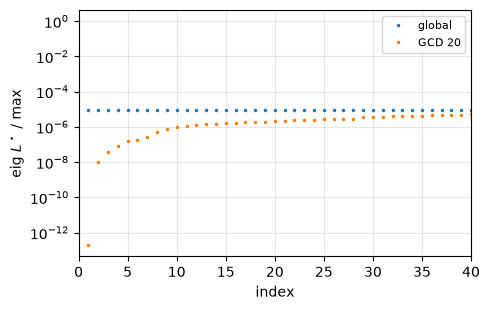

In [6]:
opt_params = OptimizationHyperparameters(opttol=1e-8,
    gradConverge=True,
    min_inner_iter=10,
    max_restart=20,
    penalty_ratio=1e-2,
    penalty_reduction=0.1,
    break_iter_period=5,
    verbose=0)

np.random.seed(0)
PlistGlob = [sp.diags(q*np.ones(Ndes, dtype=complex)) for q in [1, 1j]] # global real and reactive power
Qglob = DenseSharedProjQCQP(Obj, obj, obj0, A1, s1, PlistGlob, A2=A2, verbose=0)
t1 = time.time()
Qglob.solve_current_dual_problem(method='newton', init_lags=np.array([1.0, 0.0]), opt_params=opt_params)
dualReport("global", Qglob, time.time() - t1)

Ngcd = 20 # number of GCD iterations
Qgcd = copy.deepcopy(Qglob)
gcd_params = GCDHyperparameters(max_proj_cstrt_num=2 + 2*Ngcd,
    max_gcd_iter_num=Ngcd,
    gcd_iter_period=Ngcd + 1, # no early termination
    opt_params=opt_params)
t1 = time.time()
with contextlib.redirect_stdout(io.StringIO()): # silence the per-iteration GCD output
    Qgcd.run_gcd(gcd_params)
dualReport(f"GCD {Ngcd}", Qgcd, time.time() - t1)
print(f"bound / full plate {Qgcd.current_dual/Pfull:.0f}, bound / resonant dipole {Qgcd.current_dual/Pdip:.2f}")

fig, ax = plt.subplots(figsize=(5, 3.2))
for name, Q in [("global", Qglob), (f"GCD {Ngcd}", Qgcd)]:
    lam = lagSpectrum(Q)
    ax.semilogy(np.arange(1, Ndes + 1), lam/lam[-1], '.', ms=3, label=name)
ax.set_xlabel('index'); ax.set_ylabel(r'eig $L^\star$ / max'); ax.set_xlim(0, 40); ax.legend(fontsize=8); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

## Nullspace cascade

`qcqpParts` reads the objective and all constraints of any `DenseSharedProjQCQP` (projector and general) in the common form
$(A, s, c)$, so the reduction applies equally to the full QCQP and to an already reduced one. A level is described by the affine map
$x = a + B z$ from its variable $z$ to the full $x$; splitting $z = z_r + N y$ gives $a \leftarrow a + B z_r$, $B \leftarrow B N$.

The near-kernel of a level is relative to the largest eigenvalue of that level's Lagrangian, $\lambda_i < \epsilon\,\lambda_\mathrm{max}$, so a
reduced level resolves the near-kernel of its parent on its own scale. The cascade stops when the near-kernel is empty (the reduced
dual current is unique) or after `maxLevels`. The residuals $c(x)$ are those of the root QCQP, which are the reduced constraints at the
corresponding $y$.

In [7]:
def qcqpParts(Q):
    # objective (A0, s0, c0) and constraints [(A_k, F_k, c_k)], f(x) = -x^H A x + 2 Re(x^H s) + c
    ck = np.r_[np.zeros(Q.n_proj_constr), Q.c_2j]
    cons = [(Msym(np.asarray(Ak)), Q.Fs[:, k].copy(), ck[k]) for k, Ak in enumerate(Q.precomputed_As)]
    return (Msym(np.asarray(Q.A0)), Q.s0.copy(), float(Q.c0)), cons

def shiftForm(A, s, c, x0, N):
    # f(x0 + N y) in the same form, in y
    Ax0 = A @ x0
    return Msym(N.conj().T @ A @ N), N.conj().T @ (s - Ax0), float(np.real(-x0.conj() @ Ax0 + 2*x0.conj() @ s) + c)

def generalQCQP(objective, cons):
    # QCQP with only general constraints (A2 = 1), objective (A0, s0, c0) and constraints [(B_j, s_2j, c_2j)]
    A0r, s0r, c0r = objective
    K = len(s0r)
    return DenseSharedProjQCQP(A0r, s0r, c0r, np.eye(K, dtype=complex), np.zeros(K, dtype=complex), [], Pstruct=sp.eye(K),
                               B_j=[c[0] for c in cons], s_2j=[c[1] for c in cons], c_2j=np.array([c[2] for c in cons]), verbose=0)

def reduceQCQP(Q, x0, N):
    # QCQP of Q restricted to x = x0 + N y, all constraints general
    (A0, s0, c0), cons = qcqpParts(Q)
    return generalQCQP(shiftForm(A0, s0, c0, x0, N), [shiftForm(A, s, c, x0, N) for A, s, c in cons])

def consVec(con):
    # real coordinates of the constraint function -y^H B y + 2 Re(y^H s) + c
    B, s, c = con
    return np.r_[B.real.ravel(), B.imag.ravel(), s.real, s.imag, c]

def spanInfo(Q):
    # rank of the constraint functions of a reduced QCQP against the dimension (K + 1)^2 of all real quadratics in y, and the
    # minimal-norm multipliers mu with sum_k mu_k c_k(y) = 1 (constant in the span: the restricted primal is infeasible)
    cons = qcqpParts(Q)[1]
    M = np.array([consVec(cn) for cn in cons]).T
    sv = np.linalg.svd(M, compute_uv=False)
    e = np.zeros(M.shape[0]); e[-1] = 1.0
    mu = np.linalg.lstsq(M, e, rcond=1e-10)[0]
    return dict(rank=int(np.sum(sv > 1e-10*sv[0])), full=(len(cons[0][1]) + 1)**2, constRes=np.linalg.norm(M @ mu - e),
                muNorm=np.linalg.norm(mu))

def splitKernel(Q, kerTol):
    # near-kernel N of L* (eig < kerTol max eig) and the fixed range part of x*
    lam, U = np.linalg.eigh(Msym(Q._get_total_A(Q.current_lags)))
    N = U[:, lam < kerTol*lam[-1]]
    xs = Q.current_xstar
    return lam, N, xs - N @ (N.conj().T @ xs)

def setLags(Q, lags):
    Q.current_lags = lags
    Q.current_dual = Q.get_dual(lags)[0]
    Q.current_xstar = Q._get_xstar(lags)[0]

class EvalCap(Exception):
    pass

def solveReduced(Qr, lags, maxEval=3000):
    # start from (1 + t) lags, the smallest t in the list that is strictly dual feasible. The optimizer has no iteration limit and a
    # reduced dual can be unbounded below (infeasible restricted primal, see Kernel GCD), so get_dual is capped at maxEval calls and
    # the multipliers with the lowest unpenalized dual seen are kept. Returns t and whether the cap was hit.
    t = next(t for t in [1e-6, 1e-4, 1e-2, 1e-1, 1.0, 10.0] if Qr.is_dual_feasible((1 + t)*lags))
    l0 = (1 + t)*lags
    best = [Qr.get_dual(l0)[0], l0.copy()]
    count = [0]
    getDual = Qr.get_dual
    def cappedDual(l, *args, **kwargs):
        count[0] += 1
        if count[0] > maxEval:
            raise EvalCap
        out = getDual(l, *args, **kwargs)
        D = out[0] if not kwargs.get("penalty_vectors") else getDual(l)[0]
        if D < best[0]:
            best[0], best[1] = D, np.array(l, dtype=float).copy()
        return out
    Qr.get_dual = cappedDual
    capped = False
    try:
        Qr.solve_current_dual_problem(method='newton', init_lags=l0, opt_params=opt_params)
    except EvalCap:
        capped = True
    finally:
        del Qr.get_dual
    if capped or Qr.current_dual > best[0]:
        setLags(Qr, best[1])
    return t, capped

def cascade(Q, kerTol=1e-6, maxLevels=10, kerGCD=0):
    # kerGCD > 0: after the reduced solve, kerGCD iterations of GCD inside the kernel (kernelGCD, below)
    a, B = np.zeros(Ndes, dtype=complex), np.eye(Ndes, dtype=complex)
    Qc, levels = Q, []
    for lev in range(maxLevels + 1):
        lam, N, zr = splitKernel(Qc, kerTol)
        x = a + B @ Qc.current_xstar
        I = VtoI(x)
        levels.append(dict(level=lev, dim=B.shape[1], K=N.shape[1], D=Qc.current_dual, lam=lam, x=x, Q=Qc,
                           res=np.linalg.norm(constraintRes(Q, x))/Q.current_dual, P=evalObj(I),
                           w=np.abs(localViolation(I)).max()/np.abs(I.conj() @ Vinc),
                           lamAbs=lam[0]/(levels[0]["lam"][-1] if levels else lam[-1]), # min eig / max eig of the root L*
                           ncon=Qc.n_proj_constr + Qc.n_gen_constr, span=spanInfo(Qc) if lev > 0 else None))
        if N.shape[1] == 0 or lev == maxLevels:
            break
        Qr = reduceQCQP(Qc, zr, N)
        Dlam = Qr.get_dual(Qc.current_lags)[0] if Qr.is_dual_feasible(Qc.current_lags) else np.nan
        levels[-1]["DredStart"] = Dlam # reduced dual at the parent multipliers, equal to the parent dual
        levels[-1]["t"], levels[-1]["capped"] = solveReduced(Qr, Qc.current_lags)
        levels[-1]["dlag"] = np.linalg.norm(Qr.current_lags - Qc.current_lags)/np.linalg.norm(Qc.current_lags)
        levels[-1]["dx"] = np.linalg.norm(a + B @ zr + B @ N @ Qr.current_xstar - x)/np.linalg.norm(x)
        if kerGCD:
            levels[-1]["Dsolve"] = Qr.current_dual
            Qr, levels[-1]["gcd"] = kernelGCD(Qr, a + B @ zr, B @ N, kerGCD)
        a, B, Qc = a + B @ zr, B @ N, Qr
    return levels

def cascadeReport(name, levels):
    print(name)
    for r in levels:
        extra = "" if "DredStart" not in r else f", reduced dual at parent lags - D {r['DredStart'] - r['D']:+.1e}, start t {r['t']:.0e}{', capped' if r['capped'] else ''}, |dlambda|/|lambda| {r['dlag']:.1e}, |dx|/|x| {r['dx']:.1e}"
        span = "" if r["span"] is None else (f", span {r['span']['rank']}/{r['span']['full']}, "
                                             f"const. residual {r['span']['constRes']:.0e}, |mu| {r['span']['muNorm']:.1e}")
        gcd = "" if "gcd" not in r else f", kernel GCD: +{r['gcd']['added']} constraints, {r['gcd']['capped']} capped solves, D {r['Dsolve']:.8e} -> {r['gcd']['hist'][-1]:.8e}"
        print(f"  level {r['level']}: dim {r['dim']:3d}, {r['ncon']} constraints, near-kernel {r['K']:3d}, D {r['D']:.8e} W, "
              f"min eig / max: level {r['lam'][0]/r['lam'][-1]:.1e}, root {r['lamAbs']:.1e}, "
              f"||c||/D {r['res']:.1e}, P(I)/D {r['P']/r['D']:.4f}, max|w_i|/|I^H V| {r['w']:.1e}" + span + extra + gcd)

In [8]:
kerTols = [1e-8, 1e-6, 1e-4]
cascades = {}
for root, Q in [("global", Qglob), ("GCD", Qgcd)]:
    for kerTol in kerTols:
        t1 = time.time()
        cascades[root, kerTol] = cascade(Q, kerTol)
        cascadeReport(f"{root}, eps {kerTol:.0e} ({time.time() - t1:.1f}s)", cascades[root, kerTol])

# checks: the reduced dual equals the parent dual at the parent multipliers and never exceeds it after the solve
for key, levels in cascades.items():
    for p, r in zip(levels[:-1], levels[1:]):
        assert abs(p["DredStart"] - p["D"]) < 1e-6*p["D"], key
        assert r["D"] <= p["D"]*(1 + 1e-9), key
        assert r["K"] < p["K"] or r["K"] == 0, key
print("cascade checks passed")

global, eps 1e-08 (0.0s)
  level 0: dim 233, 2 constraints, near-kernel   0, D 1.84794400e+01 W, min eig / max: level 8.7e-06, root 8.7e-06, ||c||/D 2.3e-04, P(I)/D 1.0000, max|w_i|/|I^H V| 4.0e+01
global, eps 1e-06 (0.0s)
  level 0: dim 233, 2 constraints, near-kernel   0, D 1.84794400e+01 W, min eig / max: level 8.7e-06, root 8.7e-06, ||c||/D 2.3e-04, P(I)/D 1.0000, max|w_i|/|I^H V| 4.0e+01
global, eps 1e-04 (0.1s)
  level 0: dim 233, 2 constraints, near-kernel 163, D 1.84794400e+01 W, min eig / max: level 8.7e-06, root 8.7e-06, ||c||/D 2.3e-04, P(I)/D 1.0000, max|w_i|/|I^H V| 4.0e+01, reduced dual at parent lags - D -4.6e-14, start t 1e-06, |dlambda|/|lambda| 4.0e-05, |dx|/|x| 6.4e-06
  level 1: dim 163, 2 constraints, near-kernel   0, D 1.84794400e+01 W, min eig / max: level 9.4e-02, root 8.7e-06, ||c||/D 3.1e-05, P(I)/D 1.0000, max|w_i|/|I^H V| 4.0e+01, span 2/26896, const. residual 1e-01, |mu| 5.6e-01


/Users/xjliska/GIT/dolphindes/.venv/lib/python3.12/site-packages/scipy/sparse/linalg/_eigen/arpack/arpack.py:1664: RuntimeWarning: k >= N - 1 for N * N square matrix. Attempting to use scipy.linalg.eig instead.
  ret = eigs(A, k, M=M, sigma=sigma, which=which, v0=v0,


GCD, eps 1e-08 (0.4s)
  level 0: dim 233, 42 constraints, near-kernel   2, D 1.77349727e+01 W, min eig / max: level 1.9e-13, root 1.9e-13, ||c||/D 4.1e-03, P(I)/D 1.0000, max|w_i|/|I^H V| 5.7e+01, reduced dual at parent lags - D -1.4e-09, start t 1e-06, |dlambda|/|lambda| 9.2e-07, |dx|/|x| 1.4e+00
  level 1: dim   2, 42 constraints, near-kernel   0, D 1.77349727e+01 W, min eig / max: level 3.8e-06, root 3.8e-14, ||c||/D 4.0e-02, P(I)/D 0.9988, max|w_i|/|I^H V| 2.4e+02, span 9/9, const. residual 2e-12, |mu| 9.5e+05


GCD, eps 1e-06 (0.9s)
  level 0: dim 233, 42 constraints, near-kernel   9, D 1.77349727e+01 W, min eig / max: level 1.9e-13, root 1.9e-13, ||c||/D 4.1e-03, P(I)/D 1.0000, max|w_i|/|I^H V| 5.7e+01, reduced dual at parent lags - D -1.4e-09, start t 1e-06, |dlambda|/|lambda| 6.8e-07, |dx|/|x| 1.4e+00
  level 1: dim   9, 42 constraints, near-kernel   1, D 1.77349727e+01 W, min eig / max: level 4.0e-08, root 2.9e-14, ||c||/D 4.0e-02, P(I)/D 0.9988, max|w_i|/|I^H V| 2.4e+02, span 42/100, const. residual 2e-02, |mu| 1.1e+05, reduced dual at parent lags - D +3.6e-15, start t 1e-06, |dlambda|/|lambda| 1.2e-03, |dx|/|x| 7.3e-01
  level 2: dim   1, 42 constraints, near-kernel   0, D 1.77349726e+01 W, min eig / max: level 1.0e+00, root 7.7e-14, ||c||/D 4.1e-03, P(I)/D 1.0000, max|w_i|/|I^H V| 5.9e+01, span 4/4, const. residual 4e-13, |mu| 2.1e+04


GCD, eps 1e-04 (1.9s)
  level 0: dim 233, 42 constraints, near-kernel 162, D 1.77349727e+01 W, min eig / max: level 1.9e-13, root 1.9e-13, ||c||/D 4.1e-03, P(I)/D 1.0000, max|w_i|/|I^H V| 5.7e+01, reduced dual at parent lags - D -1.4e-09, start t 1e-06, |dlambda|/|lambda| 1.0e-06, |dx|/|x| 1.4e+00
  level 1: dim 162, 42 constraints, near-kernel   1, D 1.77349727e+01 W, min eig / max: level 9.4e-11, root 9.1e-15, ||c||/D 4.0e-02, P(I)/D 0.9988, max|w_i|/|I^H V| 2.4e+02, span 42/26569, const. residual 9e-02, |mu| 8.0e+02, reduced dual at parent lags - D +3.6e-15, start t 1e-06, |dlambda|/|lambda| 9.7e-07, |dx|/|x| 7.0e-01
  level 2: dim   1, 42 constraints, near-kernel   0, D 1.77349727e+01 W, min eig / max: level 1.0e+00, root 5.3e-14, ||c||/D 6.2e-03, P(I)/D 1.0000, max|w_i|/|I^H V| 6.7e+01, span 4/4, const. residual 7e-13, |mu| 2.6e+04
cascade checks passed


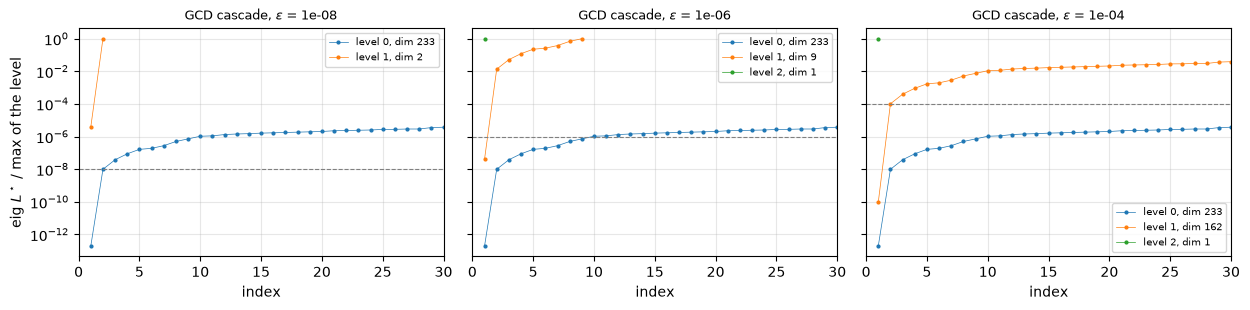

In [9]:
fig, axes = plt.subplots(1, len(kerTols), figsize=(4.2*len(kerTols), 3.2), sharey=True)
for ax, kerTol in zip(axes, kerTols):
    for r in cascades["GCD", kerTol]:
        ax.semilogy(np.arange(1, len(r["lam"]) + 1), r["lam"]/r["lam"][-1], '.-', ms=4, lw=0.5,
                    label=f"level {r['level']}, dim {r['dim']}")
    ax.axhline(kerTol, ls='--', c='gray', lw=0.8)
    ax.set_xlim(0, 30); ax.set_xlabel('index'); ax.set_title(rf"GCD cascade, $\epsilon$ = {kerTol:.0e}", fontsize=9)
    ax.legend(fontsize=7); ax.grid(True, which='both', alpha=0.3)
axes[0].set_ylabel(r'eig $L^\star$ / max of the level')
plt.tight_layout(); plt.show()

## Kernel GCD

The cascade above reuses the parent constraint set, so a reduced level can only recombine constraints the root dual already had. Here each
reduced level is refined by GCD inside the kernel, `kernelGCD`, which mirrors `run_gcd` (`gcd.py`) for a QCQP with general constraints only:

1. at the full-space current $x = a + B y^\star$, the max-violation projector $p = (2 s_1 - A_1^H x) \odot \overline{A_2 x}$ and the min-eigenvalue
   projector $p = (A_1^H v) \odot \overline{A_2 v}$ (unit modulus), $v = B u$ with $u$ the lowest eigenvector of the reduced Lagrangian,
2. each diagonal projector constraint $\operatorname{Re}(-x^H A_1 P A_2 x + 2 x^H A_2^H P^H s_1)$ mapped to a general constraint in $y$ by `shiftForm`,
   made orthogonal to the span of the current constraints (Euclidean in the coordinates $(B, s, c)$ of the quadratic function) and normalized,
   with multiplier 0, so the dual is unchanged; a projector already in the span is dropped,
3. the leading constraints merged by their multipliers into one once there are more than `maxCon` (as `merge_lead_constraints`),
4. the reduced dual solved again from the multipliers scaled by $1 + t$.

**Span.** A constraint function in $y \in \mathbb C^K$, $-y^H B y + 2\operatorname{Re}(y^H s) + c$, lives in a real space of dimension $(K + 1)^2$, and
the dual depends only on the span of the constraint functions. If the parent constraints already span it, no projector adds anything,
and since the constant function is then in the span (multipliers $\mu$ with $\sum_k \mu_k c_k \equiv 1$), the restricted primal is
infeasible and the reduced dual is unbounded below along $-\mu$ (the Lagrangian matrix and linear term do not change). The cascade report
prints this rank against $(K + 1)^2$, the residual of the constant, and $|\mu|$ (the dual drops by $1/|\mu|$ per unit multiplier step).

In [10]:
def projectorForm(p, a, B):
    # diagonal projector constraint Re(-x^H A1 P A2 x + 2 x^H A2^H P^H s1) at x = a + B y, as a general constraint in y
    return shiftForm(Msym(A1 @ (p[:, None]*A2)), A2.conj().T @ (np.conj(p)*s1), 0.0, a, B)

def addConstraint(cons, lags, new, tol=1e-8):
    # new constraint orthogonal to the span of cons, normalized, multiplier 0; dropped if it lies in the span
    M = np.array([consVec(cn) for cn in cons]).T
    v = consVec(new)
    g = np.linalg.lstsq(M, v, rcond=None)[0]
    B, s, c = new
    for gk, (Bk, sk, ck) in zip(g, cons):
        B, s, c = B - gk*Bk, s - gk*sk, c - gk*ck
    nrm = np.linalg.norm(consVec((B, s, c)))
    if nrm < tol*np.linalg.norm(v):
        return cons, lags, False
    return cons + [(B/nrm, s/nrm, c/nrm)], np.r_[lags, 0.0], True

def mergeLead(cons, lags, m):
    # the first m constraints merged by their multipliers into one (normalized), the dual is unchanged
    merged = [sum(l*cn[i] for l, cn in zip(lags[:m], cons[:m])) for i in range(3)]
    nrm = np.linalg.norm(consVec(merged))
    return [tuple(t/nrm for t in merged)] + cons[m:], np.r_[nrm, lags[m:]]

def kernelGCD(Qr, a, B, nIter=20, maxCon=None):
    # GCD inside the kernel x = a + B y of a reduced QCQP with general constraints only
    objective, cons = qcqpParts(Qr)
    maxCon = maxCon or len(cons) + 2*nIter
    hist, added, capped = [Qr.current_dual], 0, 0
    for it in range(nIter):
        lags = Qr.current_lags.copy()
        x = a + B @ Qr.current_xstar
        pV = (2*s1 - A1.conj().T @ x) * np.conj(A2 @ x) # max-violation projector
        u = np.linalg.eigh(Msym(Qr._get_total_A(lags)))[1][:, 0]
        v = B @ u
        pE = (A1.conj().T @ v) * np.conj(A2 @ v) # min-eigenvalue projector, unit modulus
        pE = np.divide(pE, np.abs(pE), out=np.zeros_like(pE), where=np.abs(pE) > 0)
        n0 = len(cons)
        for p in [pV, pE]:
            cons, lags, ok = addConstraint(cons, lags, projectorForm(p, a, B))
        if len(cons) == n0: # both projectors already in the span
            break
        added += len(cons) - n0
        if len(cons) > maxCon:
            cons, lags = mergeLead(cons, lags, len(cons) - maxCon + 1)
        Qr = generalQCQP(objective, cons)
        capped += solveReduced(Qr, lags)[1]
        hist.append(Qr.current_dual)
    return Qr, dict(hist=np.array(hist), added=added, capped=capped)

# check: at x = a + B y the mapped projector constraint equals the full-space one
rng = np.random.default_rng(1)
Bt = np.linalg.qr(rng.standard_normal((Ndes, 3)) + 1j*rng.standard_normal((Ndes, 3)))[0]
at, yt = Qgcd.current_xstar, rng.standard_normal(3) + 1j*rng.standard_normal(3)
pt = rng.standard_normal(Ndes) + 1j*rng.standard_normal(Ndes)
Bq, sq, cq = projectorForm(pt, at, Bt)
xt = at + Bt @ yt
full = constraintRes(DenseSharedProjQCQP(Obj, obj, obj0, A1, s1, [sp.diags(pt)], A2=A2), xt)[0] # the library's projector constraint
print(f"projectorForm check: relative error {abs(np.real(-yt.conj() @ Bq @ yt + 2*yt.conj() @ sq) + cq - full)/abs(full):.1e}")

projectorForm check: relative error 7.3e-15


In [11]:
NgcdKer = 20 # GCD iterations per reduced level
cascadesGCD = {}
for root, Q, tols in [("global", Qglob, [1e-4]), ("GCD", Qgcd, kerTols)]:
    for kerTol in tols:
        t1 = time.time()
        cascadesGCD[root, kerTol] = cascade(Q, kerTol, kerGCD=NgcdKer)
        cascadeReport(f"{root} + kernel GCD, eps {kerTol:.0e} ({time.time() - t1:.1f}s)", cascadesGCD[root, kerTol])
for key, levels in cascadesGCD.items():
    for p, r in zip(levels[:-1], levels[1:]):
        assert r["D"] <= p["D"]*(1 + 1e-9), key
print("kernel GCD: the reduced duals never exceed the parent dual")

print("\nparent set vs kernel GCD, final level (D relative to the root dual, min eig relative to the root max eig)")
for key, lg in cascadesGCD.items():
    lp = cascades[key]
    for name, lv in [("parent set", lp), ("kernel GCD", lg)]:
        r = lv[-1]
        print(f"{key[0]:6s} eps {key[1]:.0e} {name:10s}: levels {len(lv)}, final dim {r['dim']:3d}, D/D0 - 1 {r['D']/lv[0]['D'] - 1:+.2e}, "
              f"min eig/root max {r['lamAbs']:.1e}, ||c||/D0 {r['res']:.1e}, P(I)/D0 {r['P']/lv[0]['D']:.4f}, max|w_i|/|I^H V| {r['w']:.1e}")

global + kernel GCD, eps 1e-04 (42.2s)
  level 0: dim 233, 2 constraints, near-kernel 163, D 1.84794400e+01 W, min eig / max: level 8.7e-06, root 8.7e-06, ||c||/D 2.3e-04, P(I)/D 1.0000, max|w_i|/|I^H V| 4.0e+01, reduced dual at parent lags - D -4.6e-14, start t 1e-06, |dlambda|/|lambda| 4.0e-05, |dx|/|x| 6.4e-06, kernel GCD: +40 constraints, 20 capped solves, D 1.84794400e+01 -> -1.36136459e+09
  level 1: dim 163, 42 constraints, near-kernel   0, D -1.36136459e+09 W, min eig / max: level 2.3e-02, root 4.9e+04, ||c||/D 6.5e-01, P(I)/D -0.0000, max|w_i|/|I^H V| 3.1e+01, span 42/26896, const. residual 6e-02, |mu| 5.6e-01


GCD + kernel GCD, eps 1e-08 (0.4s)
  level 0: dim 233, 42 constraints, near-kernel   2, D 1.77349727e+01 W, min eig / max: level 1.9e-13, root 1.9e-13, ||c||/D 4.1e-03, P(I)/D 1.0000, max|w_i|/|I^H V| 5.7e+01, reduced dual at parent lags - D -1.4e-09, start t 1e-06, |dlambda|/|lambda| 9.2e-07, |dx|/|x| 1.4e+00, kernel GCD: +0 constraints, 0 capped solves, D 1.77349727e+01 -> 1.77349727e+01
  level 1: dim   2, 42 constraints, near-kernel   0, D 1.77349727e+01 W, min eig / max: level 3.8e-06, root 3.8e-14, ||c||/D 4.0e-02, P(I)/D 0.9988, max|w_i|/|I^H V| 2.4e+02, span 9/9, const. residual 2e-12, |mu| 9.5e+05


GCD + kernel GCD, eps 1e-06 (15.9s)
  level 0: dim 233, 42 constraints, near-kernel   9, D 1.77349727e+01 W, min eig / max: level 1.9e-13, root 1.9e-13, ||c||/D 4.1e-03, P(I)/D 1.0000, max|w_i|/|I^H V| 5.7e+01, reduced dual at parent lags - D -1.4e-09, start t 1e-06, |dlambda|/|lambda| 6.8e-07, |dx|/|x| 1.4e+00, kernel GCD: +27 constraints, 8 capped solves, D 1.77349727e+01 -> -1.71462382e+02
  level 1: dim   9, 69 constraints, near-kernel   1, D -1.71462382e+02 W, min eig / max: level 1.2e-09, root 7.2e-12, ||c||/D 1.3e-02, P(I)/D -0.1034, max|w_i|/|I^H V| 2.1e+01, span 69/100, const. residual 2e-05, |mu| 1.1e+05, reduced dual at parent lags - D +9.7e-13, start t 1e-06, |dlambda|/|lambda| 9.9e-07, |dx|/|x| 1.4e-01, kernel GCD: +0 constraints, 0 capped solves, D -1.71480260e+02 -> -1.71480260e+02
  level 2: dim   1, 69 constraints, near-kernel   0, D -1.71480260e+02 W, min eig / max: level 1.0e+00, root 2.1e-08, ||c||/D 1.2e-02, P(I)/D -0.1034, max|w_i|/|I^H V| 1.7e+01, span 4/4, const

GCD + kernel GCD, eps 1e-04 (55.7s)
  level 0: dim 233, 42 constraints, near-kernel 162, D 1.77349727e+01 W, min eig / max: level 1.9e-13, root 1.9e-13, ||c||/D 4.1e-03, P(I)/D 1.0000, max|w_i|/|I^H V| 5.7e+01, reduced dual at parent lags - D -1.4e-09, start t 1e-06, |dlambda|/|lambda| 1.0e-06, |dx|/|x| 1.4e+00, kernel GCD: +32 constraints, 8 capped solves, D 1.77349727e+01 -> -6.51736729e+04
  level 1: dim 162, 74 constraints, near-kernel   1, D -6.51736729e+04 W, min eig / max: level 7.0e-12, root 2.2e-09, ||c||/D 7.7e-03, P(I)/D -0.0003, max|w_i|/|I^H V| 1.1e+01, span 74/26569, const. residual 9e-02, |mu| 8.0e+02, reduced dual at parent lags - D +1.5e-10, start t 1e-06, capped, |dlambda|/|lambda| 1.0e-06, |dx|/|x| 3.9e-01, kernel GCD: +0 constraints, 0 capped solves, D -6.52200256e+04 -> -6.52200256e+04
  level 2: dim   1, 74 constraints, near-kernel   0, D -6.52200256e+04 W, min eig / max: level 1.0e+00, root 8.1e-05, ||c||/D 7.7e-03, P(I)/D -0.0003, max|w_i|/|I^H V| 1.1e+01, span 

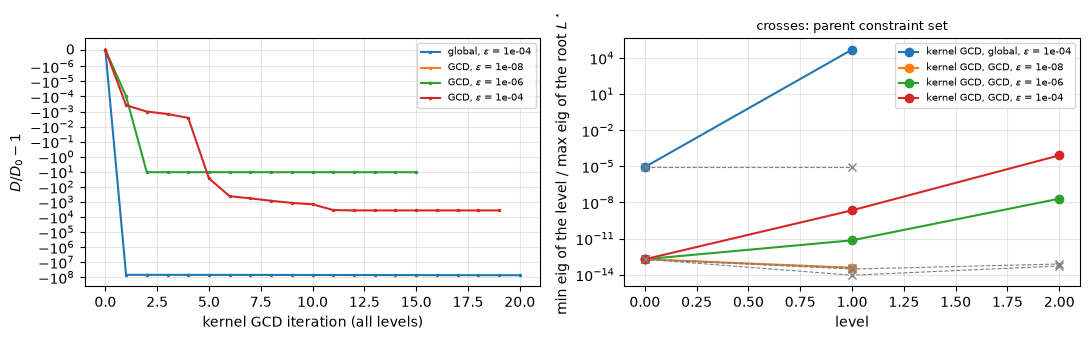

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for (root, kerTol), levels in cascadesGCD.items():
    hist = np.concatenate([r["gcd"]["hist"] for r in levels if "gcd" in r])
    axes[0].plot(hist/levels[0]["D"] - 1, '.-', ms=3, label=rf"{root}, $\epsilon$ = {kerTol:.0e}")
    axes[1].semilogy([r["level"] for r in levels], [r["lamAbs"] for r in levels], 'o-', label=rf"kernel GCD, {root}, $\epsilon$ = {kerTol:.0e}")
    axes[1].semilogy([r["level"] for r in cascades[root, kerTol]], [r["lamAbs"] for r in cascades[root, kerTol]], 'x--', c='gray', lw=0.8)
axes[0].set_yscale('symlog', linthresh=1e-6)
axes[0].set_xlabel('kernel GCD iteration (all levels)'); axes[0].set_ylabel(r'$D/D_0 - 1$'); axes[0].legend(fontsize=7); axes[0].grid(True, alpha=0.3)
axes[1].set_xlabel('level'); axes[1].set_ylabel(r'min eig of the level / max eig of the root $L^\star$')
axes[1].set_title('crosses: parent constraint set', fontsize=9); axes[1].legend(fontsize=7); axes[1].grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()

## Direct inference

The pointwise fits of `maxScatFixQ.ipynb`: the impedance form projects the inferred series impedance $r_i = (V - Z_\mathrm{tot} I)_i / I_i$ onto the
passive ray, $d_i = 1/(1 + t_i)$; the admittance form fits $Z_s L_{ii} I_i = d_i u_i$ with the driving voltage $u$ without the material self term.
Both recover the full plate exactly. The relaxed density is rounded with thresholds $t \in [10^{-6}, 1)$ and the binary design with the largest
scattered power is kept. The inference runs on the global and GCD dual currents and on the final current of every cascade.

In [13]:
dMin = 1e-6 # basis functions with d_i < dMin are removed in the realized structure
thsLog = np.logspace(-6, 0, 61)[:-1] # thresholds for binary rounding of d

def inferDimp(I):
    # impedance form: series impedance projected onto the passive ray, d = 1/(1 + t)
    nz = I != 0
    r = np.zeros(Ndes, dtype=complex)
    r[nz] = (Vinc - Ztot @ I)[nz]/I[nz] # inferred series impedance per basis function
    t = np.maximum(0, np.real(np.conj(Zs)*r)/(np.abs(Zs)**2*Ldiag))
    return np.where(nz, 1/(1 + t), 0.0)

def inferDadm(I):
    # admittance form: pointwise current fit of Zs Lii I_i = d_i u_i
    u = Vinc - Ztot @ I + Zs*Ldiag*I # driving voltage without the material self term
    b = u/(Zs*Ldiag) # current of a full material basis function driven by u
    return np.clip(np.real(np.conj(b)*I)/np.abs(b)**2, 0, 1)

def realizedCurrent(d):
    # (Ztot + diag(Zs Lii (1/d - 1))) I = V on the kept basis functions, I = 0 elsewhere
    keep = d >= dMin
    I = np.zeros(Ndes, dtype=complex)
    Zd = Ztot + np.diag(Zs*Ldiag*(1/np.maximum(d, dMin) - 1))
    I[keep] = np.linalg.solve(Zd[np.ix_(keep, keep)], Vinc[keep])
    return I

def bestBinary(d):
    # binary rounding over the thresholds, the design with the largest scattered power
    designs = [d > t for t in thsLog]
    currents = [realizedCurrent(k.astype(float)) for k in designs]
    Pb = np.array([evalObj(I) for I in currents])
    k = int(np.argmax(Pb))
    return dict(keep=designs[k], I=currents[k], P=Pb[k], th=thsLog[k])

def inferPointwise(x):
    I = VtoI(x)
    return {form: dict(d=d, Prelax=evalObj(realizedCurrent(d)), **bestBinary(d))
            for form, d in [("impedance form", inferDimp(I)), ("admittance form", inferDadm(I))]}

# check: both pointwise forms recover the full plate exactly
for form, infer in [("impedance form", inferDimp), ("admittance form", inferDadm)]:
    d = infer(Ifull)
    print(f"full plate, {form}: max |d - 1| = {np.max(np.abs(d - 1)):.2e}, realized objective {evalObj(realizedCurrent(d)):.6e} W")

full plate, impedance form: max |d - 1| = 1.15e-09, realized objective 4.114174e-02 W
full plate, admittance form: max |d - 1| = 1.15e-09, realized objective 4.114174e-02 W


In [14]:
currents = {"global x*": (Qglob.current_xstar, Qglob.current_dual), f"GCD {Ngcd} x*": (Qgcd.current_xstar, Qgcd.current_dual)}
for (root, kerTol), levels in cascades.items():
    if len(levels) > 1: # a cascade without a near-kernel returns the root x*
        currents[f"{root} cascade, eps {kerTol:.0e}"] = (levels[-1]["x"], levels[0]["D"])
for (root, kerTol), levels in cascadesGCD.items():
    if len(levels) > 1:
        currents[f"{root} cascade+kGCD, eps {kerTol:.0e}"] = (levels[-1]["x"], levels[0]["D"])

inference = {}
t1 = time.time()
for name, (x, D) in currents.items():
    inference[name] = inferPointwise(x)
    for form, r in inference[name].items():
        print(f"{name:32s} {form:16s}: relaxed P/D {r['Prelax']/D:.4f}, binary P {r['P']:.4e} W, P/D {r['P']/D:.4f}, "
              f"threshold {r['th']:.1e}, kept {r['keep'].sum()}/{Ndes}")
print(f"inference: {time.time() - t1:.1f}s")

global x*                        impedance form  : relaxed P/D 0.0027, binary P 6.2119e-02 W, P/D 0.0034, threshold 1.0e-03, kept 128/233
global x*                        admittance form : relaxed P/D 0.0006, binary P 6.4653e-02 W, P/D 0.0035, threshold 1.0e-06, kept 115/233
GCD 20 x*                        impedance form  : relaxed P/D 0.0026, binary P 4.4324e-02 W, P/D 0.0025, threshold 6.3e-04, kept 160/233
GCD 20 x*                        admittance form : relaxed P/D 0.0000, binary P 1.0701e-03 W, P/D 0.0001, threshold 1.0e-06, kept 97/233
global cascade, eps 1e-04        impedance form  : relaxed P/D 0.0027, binary P 6.2119e-02 W, P/D 0.0034, threshold 1.0e-03, kept 128/233
global cascade, eps 1e-04        admittance form : relaxed P/D 0.0006, binary P 6.4653e-02 W, P/D 0.0035, threshold 1.0e-06, kept 115/233
GCD cascade, eps 1e-08           impedance form  : relaxed P/D 0.0026, binary P 4.4567e-02 W, P/D 0.0025, threshold 1.0e-03, kept 152/233
GCD cascade, eps 1e-08           ad

GCD cascade+kGCD, eps 1e-08      impedance form  : relaxed P/D 0.0026, binary P 4.4567e-02 W, P/D 0.0025, threshold 1.0e-03, kept 152/233
GCD cascade+kGCD, eps 1e-08      admittance form : relaxed P/D 0.0000, binary P 9.5506e-04 W, P/D 0.0001, threshold 1.0e-06, kept 96/233


GCD cascade+kGCD, eps 1e-06      impedance form  : relaxed P/D 0.0025, binary P 4.1269e-02 W, P/D 0.0023, threshold 2.0e-05, kept 223/233
GCD cascade+kGCD, eps 1e-06      admittance form : relaxed P/D 0.0001, binary P 1.3743e-03 W, P/D 0.0001, threshold 1.0e-06, kept 95/233
GCD cascade+kGCD, eps 1e-04      impedance form  : relaxed P/D 0.0025, binary P 4.1832e-01 W, P/D 0.0236, threshold 1.0e-03, kept 177/233
GCD cascade+kGCD, eps 1e-04      admittance form : relaxed P/D 0.0000, binary P 1.2162e-03 W, P/D 0.0001, threshold 1.0e-06, kept 76/233
inference: 0.3s


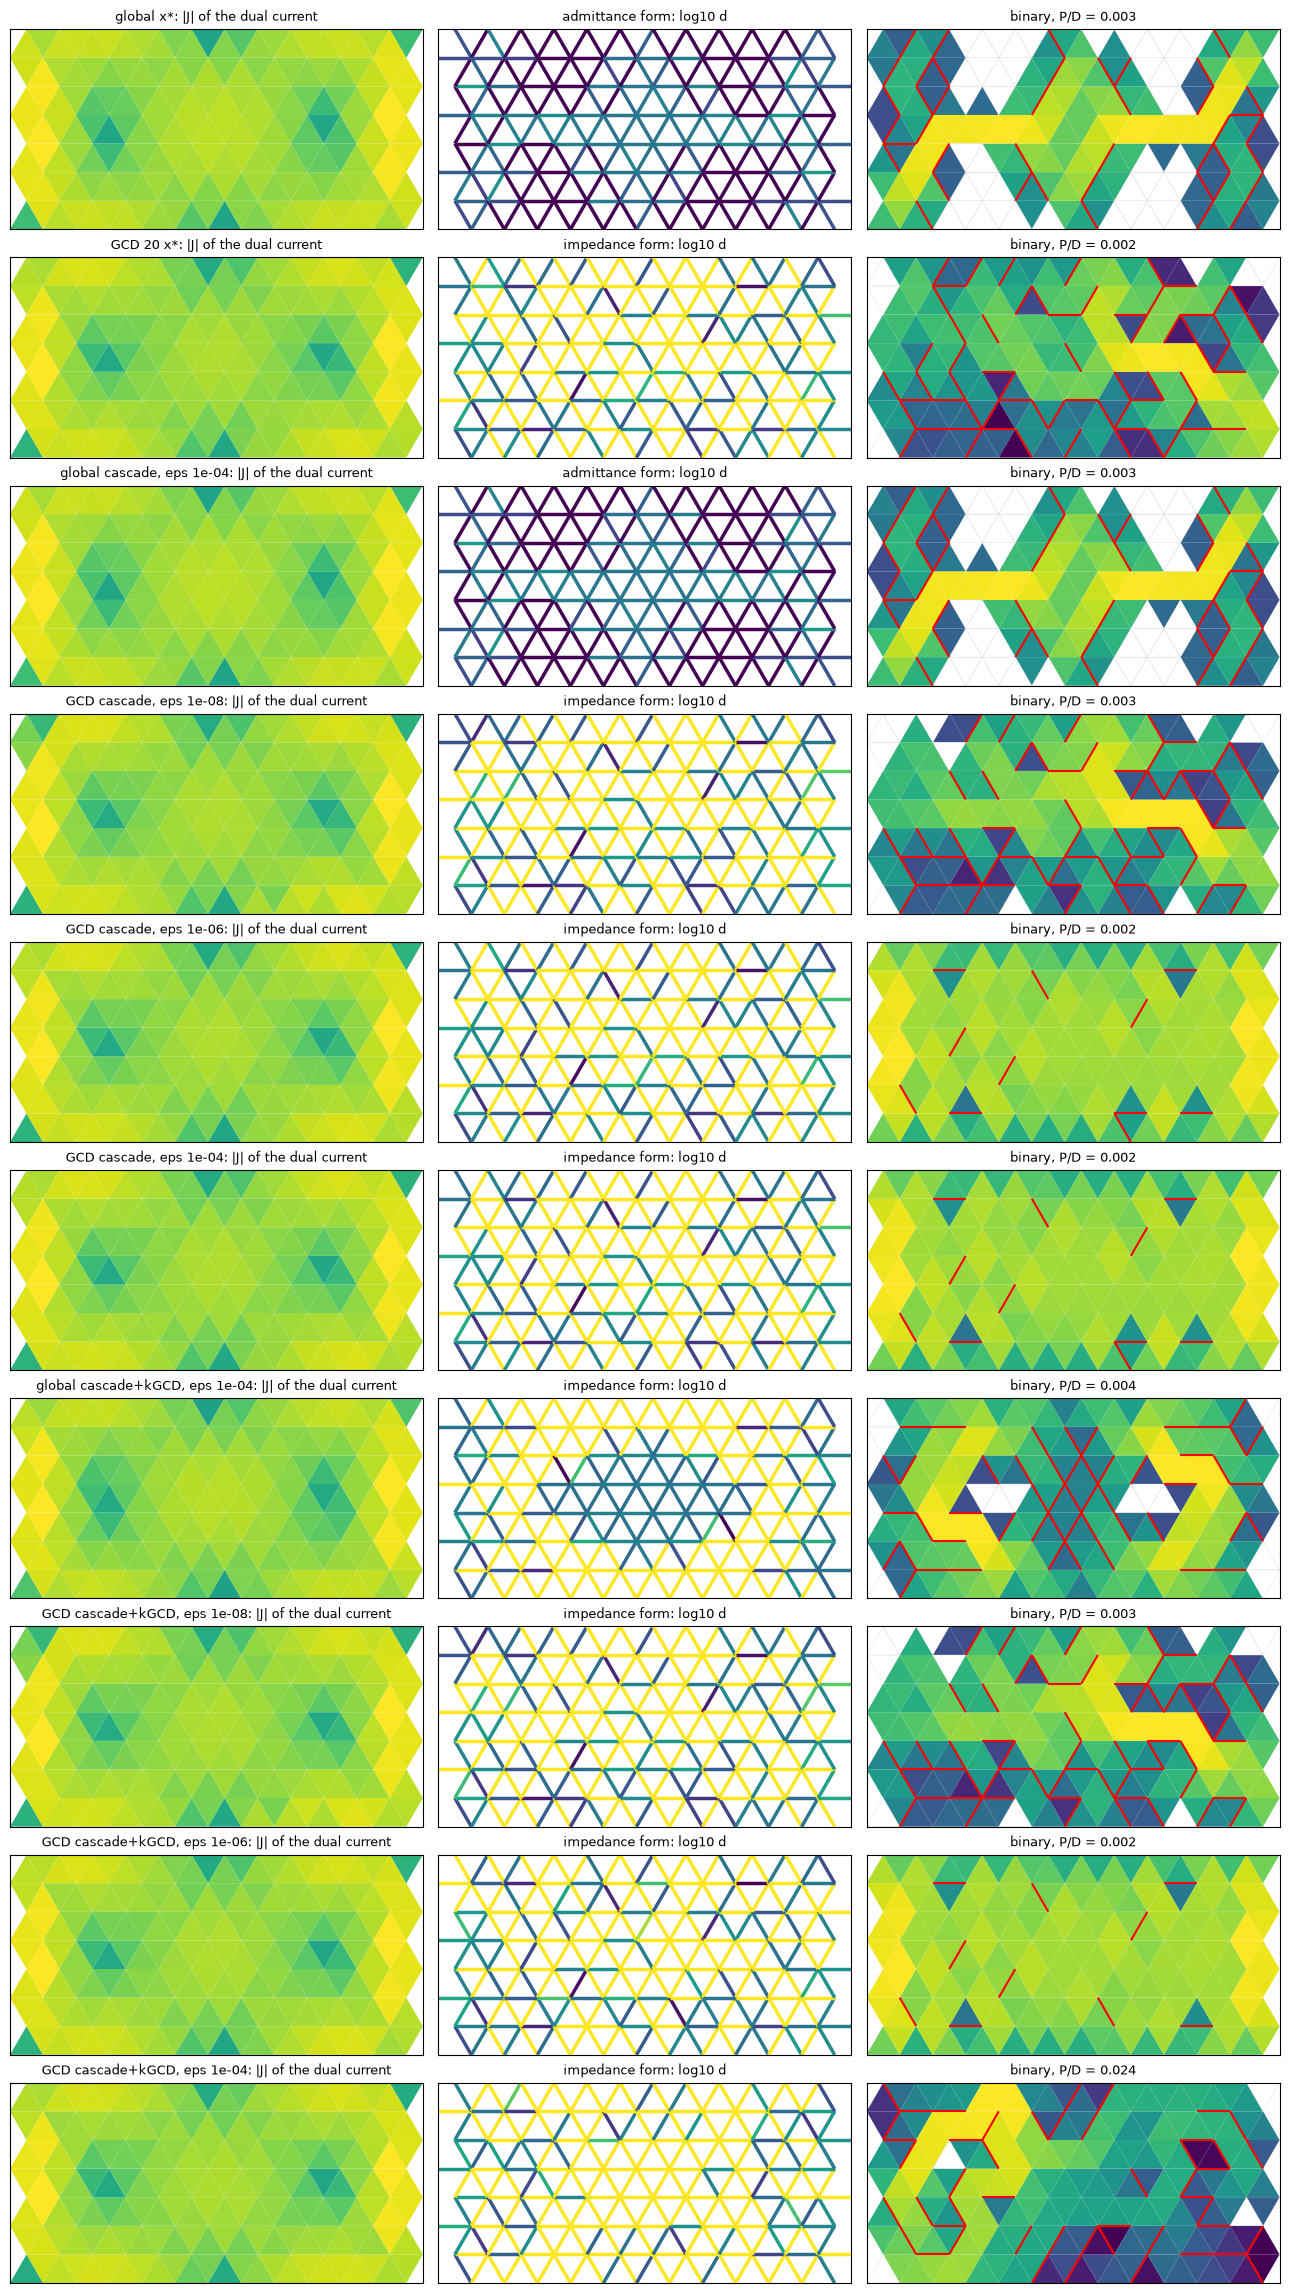

In [15]:
names = list(inference)
fig, axes = plt.subplots(len(names), 3, figsize=(13, 2.3*len(names)))
for row, name in zip(axes, names):
    x, D = currents[name]
    pc = plotStructure(row[0], np.ones(Ndes, dtype=bool), VtoI(x), f"{name}: |J| of the dual current")
    form = max(inference[name], key=lambda f: inference[name][f]["P"])
    r = inference[name][form]
    lc = plotDensity(row[1], r["d"], f"{form}: log10 d")
    plotStructure(row[2], r["keep"], r["I"], f"binary, P/D = {r['P']/D:.3f}")
plt.tight_layout(); plt.show()

## Conclusions

**Bounds.** The global bound is 18.48 W ($1.95\times$ the lossless resonant dipole). 20 GCD iterations bring it to 17.73–17.74 W. GCD is not exactly
reproducible: ARPACK starts and the random `Pstruct` coefficients shift the bound in the fifth digit between runs, and the kernel dimensions
and some cascade numbers below shift with it. The global $L^\star$ is regular (min/max eigenvalue $9\times10^{-6}$), so its cascade is trivial for
$\epsilon \leq 10^{-6}$. The GCD $L^\star$ sits on the PSD boundary (min/max $\sim 10^{-13}$). Its near-kernel has dimension 2 at $\epsilon = 10^{-8}$,
about 9 at $10^{-6}$, and about 160 at $10^{-4}$, where it includes the radiationless part of the spectrum.

**Parent constraint set: a fixed point of the dual.**
- Every reduced dual equals the parent dual at the parent multipliers to about $10^{-9}$, and the reduced solve moves the multipliers by
  no more than the start shift ($10^{-6}$–$10^{-3}$). The reduced bound equals the root bound to $10^{-9}$.
- The near-kernel "vanishes" only relative to each level's own scale. In absolute terms the final Lagrangian is still
  $\sim 10^{-13}$ of the root's largest eigenvalue.
- The kernel component that the cascade selects is a ratio of near-zero numbers and is set by the start shift.
- A span argument explains this. At a 2-D level the 42 parent constraints already span all $(K+1)^2 = 9$ real quadratics in $y$. The
  constant function is then in the span, so the restricted primal is infeasible and the reduced dual is unbounded below. The descent rate
  along the constant direction is $1/|\mu| \sim 10^{-6}$ W per unit multiplier step, so for any practical solve the dual stays at $D$.

**Kernel GCD: the restricted primal is infeasible.** With projectors generated inside the kernel ($\epsilon = 10^{-6}$ and $10^{-4}$, and the
global $L^\star$ at $10^{-4}$), the new constraints give the constant-function direction a usable slope ($|\mu| \sim 10^3$ at $\epsilon = 10^{-4}$),
and the reduced dual runs away:
- $D \to -171$ W at $\epsilon = 10^{-6}$;
- $D \to -6.5\times10^4$ W at $10^{-4}$;
- $D \to -1.4\times10^9$ W from the global solution.

The optimizer has no iteration limit, so `solveReduced` caps the dual evaluations and keeps the lowest dual seen; these values are where
the cap hit, not converged values.

So, on the three points:
1. **The reduced dual drops below $D$, but as a certificate of infeasibility, not as a tighter bound.** Fixing the range part $x_r$ of the
   dual current is inconsistent with the pointwise constraints. A restricted problem with a fixed $x_r$ bounds nothing about the original
   QCQP, and only the root $D$ remains a bound.
2. **The near-kernel closes in absolute terms only partly.** The final minimum eigenvalue relative to the root's maximum rises from
   $\sim 10^{-13}$ (parent set) to $2\times10^{-8}$ ($\epsilon = 10^{-6}$) and $8\times10^{-5}$ ($\epsilon = 10^{-4}$). At $\epsilon = 10^{-8}$ the 2-D level is
   already spanned, the kernel GCD adds nothing, and the result equals the parent cascade. From the global solution the multipliers grow
   large enough that the reduced Lagrangian scale exceeds the root's.
3. **Pointwise inference improves in one case.**
   - The final currents keep $P(I)/D_0 = 0.997$–$1$, but the pointwise violation $\max|w_i|/|I^H V|$ falls from 40–60 to 17 ($10^{-6}$) and
     11 ($10^{-4}$).
   - The impedance-form inference of the $\epsilon = 10^{-4}$ kernel-GCD current gives 0.42 W ($P/D = 2.4$ %). That is 10 times every other
     current (0.04–0.07 W, 0.2–0.4 %).
   - The other kernel-GCD currents give the same structures as the parent cascade.

   Because the reduced duals are capped runaways, the 0.42 W design comes from a well-defined heuristic but is a single run-dependent
   sample, not a converged result.

**Relation to the `preconditioner` branch.** The library GCD with a constant shift on the `preconditioner` branch (`i1`, constraints at
$x + i_1$) has the same ingredients:
- the shifted max-violation projector $(2 s_1 - A_1^H(x + i_1)) \odot \overline{A_2(x + i_1)}$;
- the linear and constant terms of the shifted projector constraint;
- an augmented metric over (quadratic, linear, constant) for orthonormalization.

`kernelGCD` uses the same pieces, as general constraints, through `projectorForm` and the orthogonalization in $(B, s, c)$. A reduced
level is $x = a + B y$ with a rectangular $B$ and $a \notin \operatorname{range} B$, which the branch's projector form (square $A_1$, $A_2$
and a shift in the same space) does not express directly.

**Outlook.** The cascade's premise, fixing $x_r$, is the weak point: once the kernel GCD makes the dual informative, it shows that
$x_r + N y$ contains no feasible point. Options:
- let the range part move as well, e.g. a trust region around $x_r$ in place of an equality, or the kernel completion of
  `maxScatFixQ.ipynb`;
- regularize the hard case physically, as the fixed $Q_W$ constraint does;
- use the kernel GCD current only as an inference target. The pointwise violation drops, and the best design improves at $\epsilon = 10^{-4}$.